# <center>🚀 Практика 9. Веб-сервис на Flask для распознавания рукописных цифр</center>
### <center>Прикладные технологии ИИ · 120 минут (2 ч.) · Модуль 5</center>

<div style='background-color: #E8F5E9; padding: 15px; border-left: 5px solid #2E7D32; margin: 20px 0;'>
<b>🎯 Цель:</b> Представить ранее обученную модель распознавания рукописных цифр (Практика 6, <code>mnist_cnn.pth</code>) в виде веб-сервиса (API), выполнить локальное развёртывание и функциональное тестирование.
<br><br>
<b>⏱️ Ход работы (120 мин):</b> 
<ul>
<li>30 мин — Часть А (создание Flask-приложения с endpoint <code>/predict</code>)</li>
<li>15 мин — Часть Б (запуск сервера: локальное развёртывание)</li>
<li>30 мин — Часть В (функциональное тестирование API через <code>requests.post</code>)</li>
<li>45 мин — Часть Г (мини-проект в группах по 3–4 человека, защита по 3 минуты на группу)</li>
</ul>
<i>Незавершённые части проекта доделываются дома, отчёт сдаётся на следующем занятии.</i>
</div>

## 📖 Введение: веб-сервис как способ «упаковки» ML-модели

Обученная нейросеть — это, в сущности, функция `y = f(x)`: на вход подаём тензор,
на выходе получаем предсказание. Однако конечному пользователю (аналитику, веб-разработчику,
обычному человеку в браузере) не нужно устанавливать Python, PyTorch и веса модели — ему нужен
**интерфейс**, через который можно отправить данные и получить ответ. Именно эту задачу решает
**веб-сервис**: он «оборачивает» модель в HTTP-интерфейс, доступный по сети.

**Flask** — это микрофреймворк для Python, который позволяет создать рабочий HTTP-сервер
всего из десятка строк кода. Слово «микро» здесь не означает, что он предназначен только
для маленьких проектов: речь о минимализме ядра. Flask не навязывает ORM, форму ввода или
шаблонизатор — всё это подключается по мере необходимости. Это делает его идеальным
инструментом для быстрого прототипирования ML-API.

Архитектура, которую мы используем, — классическая **клиент-серверная**. Клиент
(браузер, скрипт `requests`, мобильное приложение) отправляет HTTP-запрос; сервер
Flask принимает его, вызывает модель и возвращает ответ в формате JSON.
Для обмена данными используется стиль **REST** (Representational State Transfer):
каждый ресурс идентифицируется URL (`/predict`), а действие — HTTP-методом.

Два основных метода, с которыми мы работаем:

- **GET** — запрос на *чтение* данных (например, открыть веб-страницу).
  Параметры передаются в URL, объём ограничен, файлы передавать неудобно.
- **POST** — запрос на *отправку* данных на сервер (создание ресурса, загрузка файла).
  Тело запроса не отображается в URL, объём практически не ограничен. Именно поэтому
  для передачи изображения цифры мы используем **POST** с типом содержимого
  `multipart/form-data`: это позволяет прикрепить бинарный файл `digit.png`
  вместе с произвольными текстовыми полями.

В этой практике мы развернём модель MNIST из Практики 6 как POST-endpoint `/predict`
и протестируем его через библиотеку `requests`.


> 📌 В этой практике мы развернём модель MNIST из **Практики 6** (`mnist_cnn.pth`) как POST-endpoint `/predict` и протестируем его через библиотеку `requests`.

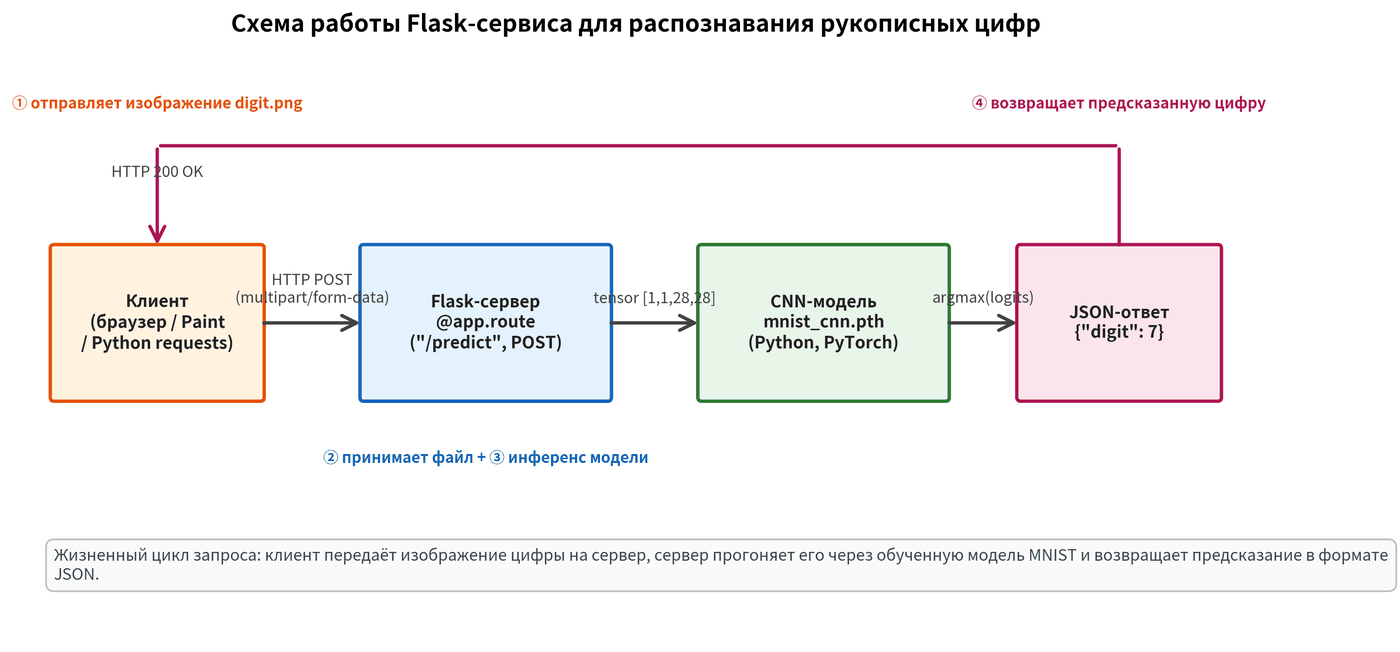

*Рис. 1. Архитектура клиент-серверного взаимодействия Flask-сервиса и CNN-модели MNIST.*

---
# ⚙️ Подготовка среды

Убедитесь, что у вас установлены необходимые библиотеки. Выполните ячейку ниже:

In [1]:
!pip install flask pillow requests -q
print('✅ Библиотеки Flask, Pillow и Requests установлены!')

✅ Библиотеки Flask, Pillow и Requests установлены!


---
# 🌐 Часть А. Создание Flask-приложения (30 мин)

Мы превратим модель из Практики 6 в настоящий веб-сервис: опишем маршрут `/predict`,
загрузим веса `mnist_cnn.pth`, выполним предобработку изображения и вернём предсказание
в формате JSON. Архитектура CNN в `app.py` должна **дословно совпадать** с архитектурой
из Практики 6 — иначе `load_state_dict` выбросит ошибку.

### Шаг 1. Создание файла `app.py`
Выполните ячейку ниже. Она создаст файл `app.py` в текущей папке. 
> ⚠️ **Важно:** Убедитесь, что файл `mnist_cnn.pth` (сохранённый в Практике 6) лежит в той же папке, что и этот ноутбук!

### 🏗️ Структура Flask-приложения: маршруты, обработка запроса, jsonify

Прежде чем писать `app.py`, разберём три ключевых понятия Flask, которые встретятся в коде:

1. **Маршрут (route).** Декоратор `@app.route('/predict', methods=['POST'])` связывает
   URL-путь с Python-функцией. Когда клиент обращается по адресу
   `http://127.0.0.1:5000/predict` методом POST, Flask вызывает именно эту функцию.
   Параметр `methods=['POST']` явно ограничивает допустимые методы — если клиент
   пришлёт GET, Flask автоматически ответит `405 Method Not Allowed`.

2. **Объект `request`.** Глобальный объект `flask.request` даёт доступ ко всему, что
   прислал клиент: `request.files` — словарь загруженных файлов
   (`multipart/form-data`), `request.form` — текстовые поля формы,
   `request.args` — параметры URL, `request.json` — тело JSON. В нашем коде
   мы читаем `request.files['image']` — это файловый объект, совместимый
   с `PIL.Image.open`.

3. **`jsonify`.** Функция `flask.jsonify(...)` превращает Python-словарь в HTTP-ответ
   с заголовком `Content-Type: application/json` и телом в формате JSON.
   Это стандартный способ возвращать структурированные данные из ML-API:
   клиенту удобно парсить ответ, а также добавлять поля (`digit`, `probabilities`,
   `latency_ms`, `model_version`).

**Жизненный цикл endpoint-функции `predict()`:**

1. Проверить, что в `request.files` есть ключ `'image'` — иначе вернуть `400 Bad Request`.
2. Открыть изображение, привести к grayscale, resize до 28×28, **инвертировать**
   (MNIST обучался на белом по чёрному, а в Paint мы рисуем чёрным по белому).
3. Преобразовать в тензор формы `[1, 1, 28, 28]` (батч × каналы × высота × ширина).
4. Выполнить прямой проход `model(x)` внутри `torch.no_grad()`, взять `argmax` по 10 классам.
5. Вернуть `jsonify({'digit': digit})` со статусом `200 OK`.

На схемах ниже показаны **пайплайн предсказания** внутри `predict()` и **общая
структура файла `app.py`**.

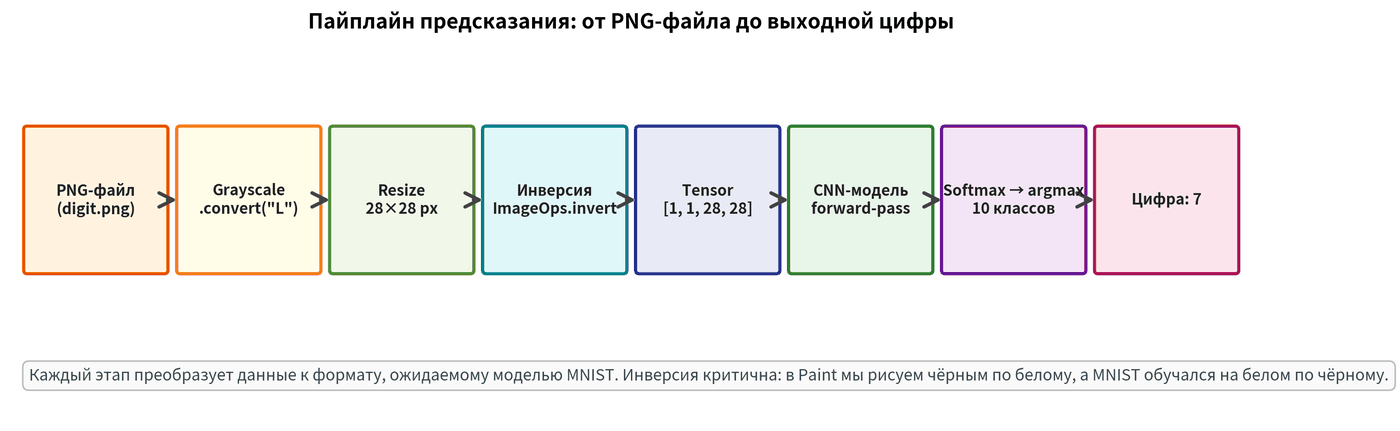

*Рис. 2. Пайплайн предобработки и инференса внутри функции predict(): от PNG-файла до выходной цифры.*

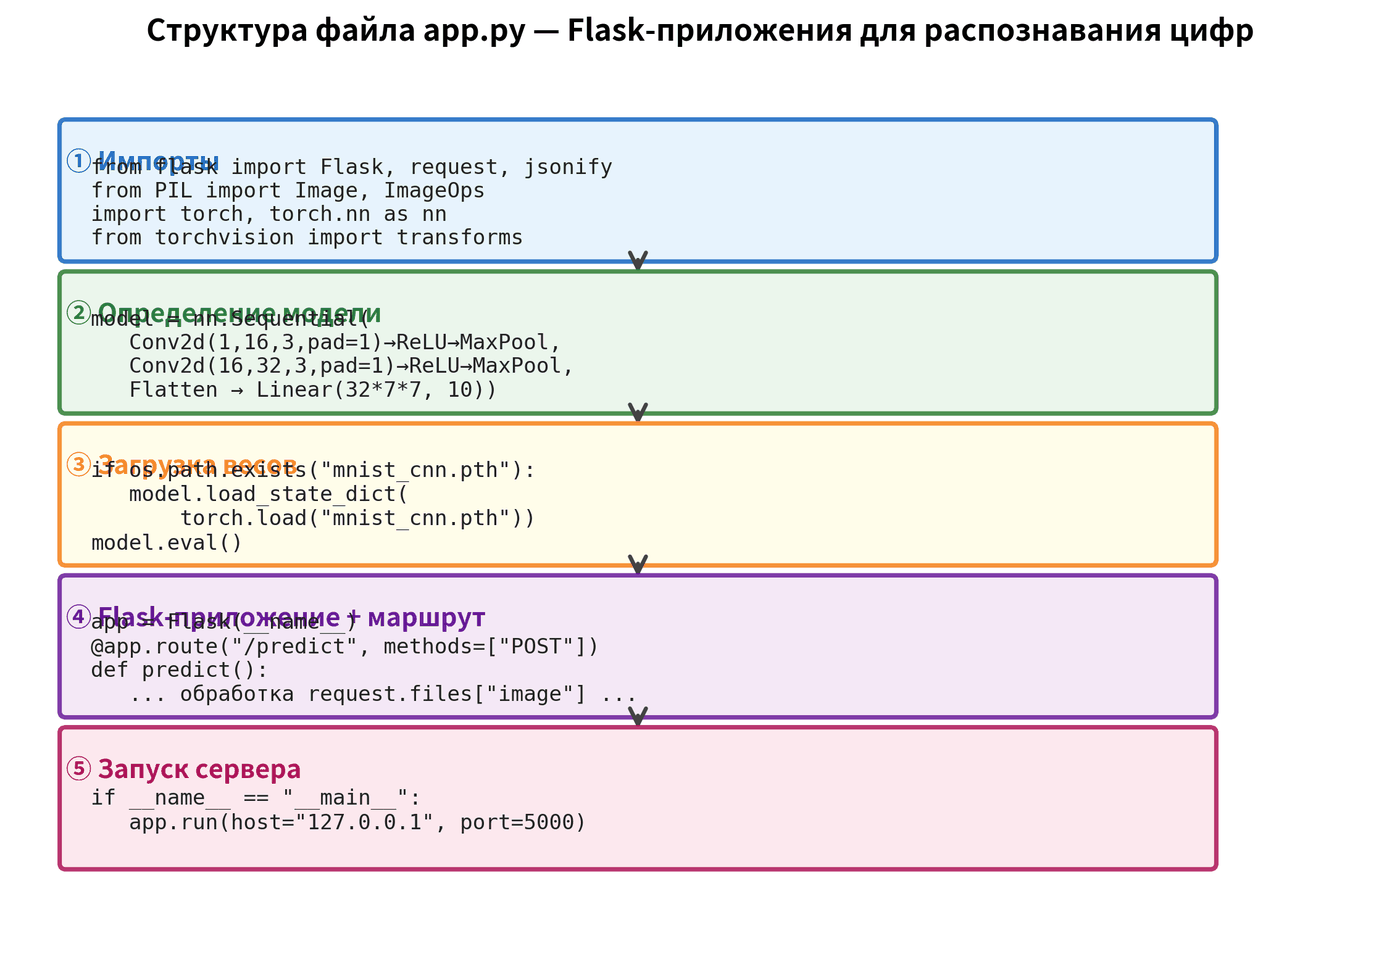

*Рис. 3. Структура файла app.py: пять логических блоков от импортов до запуска сервера.*

In [2]:
%%writefile app.py
from flask import Flask, request, jsonify
from PIL import Image, ImageOps
import torch
import torch.nn as nn
from torchvision import transforms
import os

# Та же архитектура, что в практике 6
model = nn.Sequential(
    nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Flatten(),
    nn.Linear(32 * 7 * 7, 10)
)

# Загрузка весов
if os.path.exists('mnist_cnn.pth'):
    model.load_state_dict(torch.load('mnist_cnn.pth', weights_only=True))
else:
    print("⚠️ ВНИМАНИЕ: Файл 'mnist_cnn.pth' не найден! Положите его в папку с этим скриптом.")

model.eval()

to_tensor = transforms.ToTensor()
app = Flask(__name__)

@app.route('/predict', methods=['POST'])
def predict():
    if 'image' not in request.files:
        return jsonify({'error': 'Нужен файл с ключом \"image\"'}), 400
    
    # Читаем изображение, переводим в оттенки серого и меняем размер на 28x28
    img = Image.open(request.files['image']).convert('L').resize((28, 28))
    
    # ИНВЕРСИЯ: в Paint мы рисуем чёрным по белому, а MNIST обучался на белом по чёрному
    img = ImageOps.invert(img)
    
    # Преобразуем в тензор и добавляем размерность батча: [1, 1, 28, 28]
    x = to_tensor(img).unsqueeze(0)
    
    with torch.no_grad():
        digit = model(x).argmax(1).item()
        
    return jsonify({'digit': digit})

if __name__ == '__main__':
    print("🚀 Сервер запущен! Перейдите в следующую ячейку ноутбука для тестирования.")
    app.run(host='127.0.0.1', port=5000)

Overwriting app.py


---
# 🚀 Часть Б. Запуск сервера: локальное развёртывание (15 мин)

Файл `app.py` готов — теперь запустим его как локальный HTTP-сервер и убедимся,
что он слушает порт 5000 и готов принимать POST-запросы на `/predict`.

### Шаг 2. Запуск сервера
1. Откройте **Anaconda Prompt** (или терминал).
2. Активируйте ваше окружение (например, `conda activate env_ai`).
3. Перейдите в папку с этим ноутбуком (команда `cd путь_к_папке`).
4. Запустите команду: `python app.py`
5. **Оставьте это окно открытым!** Не закрывайте его, пока не закончите тестирование.

### Шаг 3. Создание тестового изображения
Вы можете нарисовать цифру в Paint (чёрная цифра на белом фоне, толстая кисть, примерно по центру) и сохранить как `digit.png` в этой же папке.

*Для удобства тестирования код ниже автоматически создаст тестовое изображение цифры "7", если файла `digit.png` ещё нет.*

In [3]:
import os
from PIL import Image, ImageDraw

if not os.path.exists('digit.png'):
    # Создаём белое изображение 28x28 (фон)
    img = Image.new('L', (28, 28), color=255)
    draw = ImageDraw.Draw(img)
    # Рисуем чёрную цифру 7
    draw.text((8, 2), "7", fill=0, font=None)
    img.save('digit.png')
    print("✅ Тестовое изображение 'digit.png' создано автоматически!")
else:
    print("✅ Файл 'digit.png' уже существует. Будет использован ваш рисунок.")

✅ Файл 'digit.png' уже существует. Будет использован ваш рисунок.


---
# 🧪 Часть В. Функциональное тестирование API (30 мин)

После запуска сервера проведём функциональное тестирование endpoint-функции `/predict`.
ML-API тестируют по трём направлениям:
**корректность** на известных входах, **устойчивость** к плохим входам и **обработку ошибок**.

### Шаг 4. Базовый запрос к API
Теперь отправим наше тестовое изображение на сервер и получим предсказание.

### 🔌 HTTP-клиент в Python: `requests`, multipart/form-data и разбор JSON

Чтобы протестировать наш сервис, нужен **HTTP-клиент** — программа, которая
отправляет запросы и читает ответы. В Python стандартом де-факто является
библиотека `requests` (не путать с модулем `urllib` из стандартной библиотеки):
она даёт лаконичный API и автоматически обрабатывает редиректы, cookies, сессии,
кодирование форм.

**Отправка файла на сервер.** В HTTP нельзя просто «прикрепить» бинарный файл к
произвольному запросу — нужен специальный формат тела `multipart/form-data`.
Библиотека `requests` скрывает детали: достаточно передать словарь
`files={'image': f}`, где `f` — открытый файловый объект. Под капотом `requests`
сам построит multipart-тело с границами (boundary), заголовком `Content-Disposition`
и правильным `Content-Type`. Ключ `'image'` в словаре должен совпадать с ключом,
который сервер ищет в `request.files['image']` — иначе Flask вернёт нашу
ошибку `400`.

**Чтение ответа.** Ответ сервера — это объект `requests.Response` с полями:
- `response.status_code` — HTTP-статус (`200` OK, `400` Bad Request, `405` Method
  Not Allowed, `500` Internal Server Error);
- `response.json()` — разбирает тело как JSON и возвращает Python-словарь;
- `response.text` — сырой текст ответа (для отладки).

**Обработка ошибок.** Сетевой запрос может завершиться неудачей по многим
причинам: сервер не запущен, занят порт, нет маршрута, превышен таймаут.
Всегда оборачивайте вызов в `try/except requests.exceptions.ConnectionError` —
это позволит дать пользователю понятное сообщение вместо необработанного
исключения. Также проверяйте `status_code`: статус `200` означает успех, всё
остальное — нужно смотреть тело ответа с описанием ошибки.

Ниже — пример визуализации запроса и ответа: что отправляет клиент и что
получает обратно, с распределением вероятностей по 10 классам цифр.

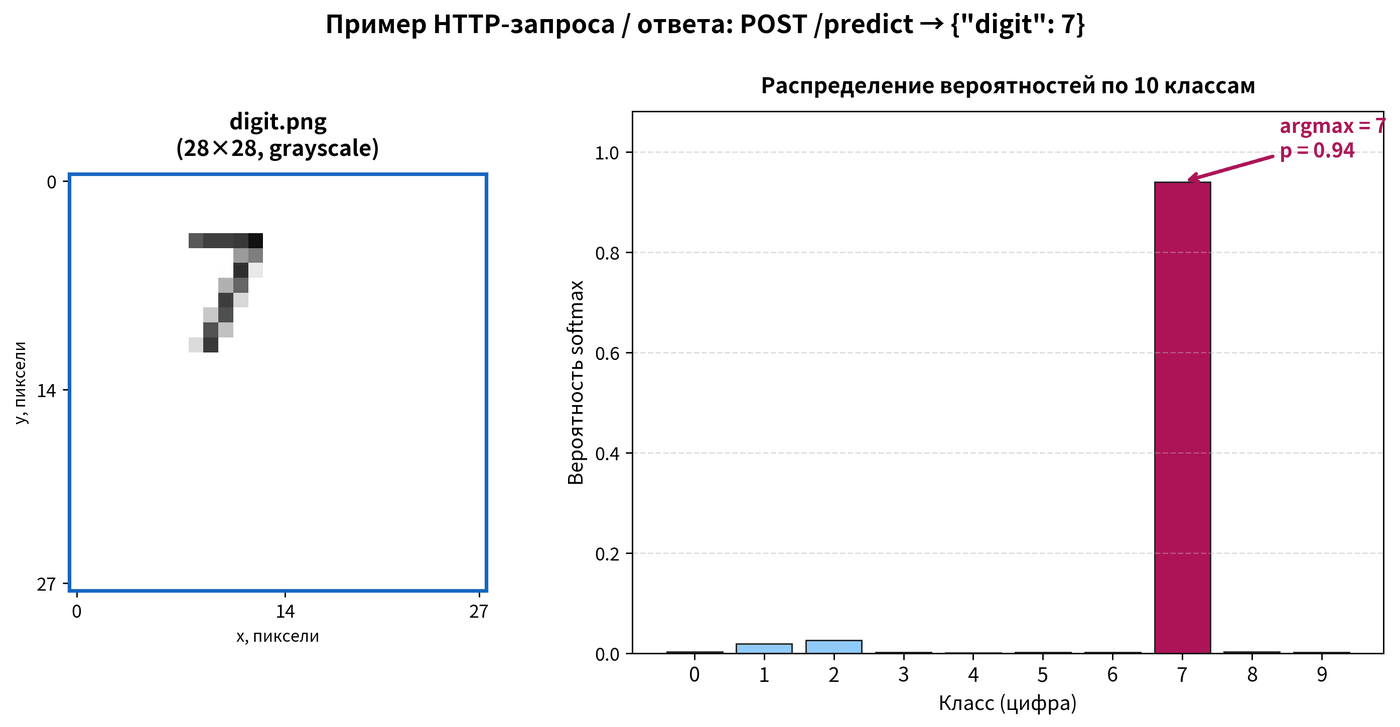

*Рис. 4. Пример POST-запроса /predict: на входе 28×28 изображение цифры «7», на выходе — распределение вероятностей softmax и итоговое предсказание.*

In [16]:
import requests

url = 'http://127.0.0.1:5000/predict'

try:
    with open('digit.png', 'rb') as f:
        # Отправляем файл с ключом 'image', как ожидает наш Flask-сервер
        response = requests.post(url, files={'image': f})
    
    if response.status_code == 200:
        result = response.json()
        print(f"🎉 Успех! Модель предсказала цифру: {result['digit']}")
    else:
        print(f"❌ Ошибка сервера: {response.status_code}")
        print(response.json())
        
except requests.exceptions.ConnectionError:
    print("❌ Ошибка соединения! Убедитесь, что вы запустили 'python app.py' в отдельном окне терминала и не закрыли его.")

🎉 Успех! Модель предсказала цифру: 2


### 📋 Что тестировать при функциональном тестировании

При тестировании ML-API проверяют три класса сценариев:

1. **Корректность ответа на известных входах.** Для каждой цифры 0–9 нарисовать
   эталонное изображение и сравнить предсказание с ожидаемой меткой. Это аналог
   unit-тестов для модели — он показывает, что пайплайн предобработки и инференса
   не сломался при упаковке в веб-сервис.

2. **Устойчивость к «плохим» входам.** Изображения с шумом, со смещением цифры
   от центра, с другой толщиной линии, повёрнутые на небольшой угол. Хорошая
   модель должна вести себя предсказуемо: либо давать верный ответ, либо
   возвращать низкую уверенность.

3. **Обработка ошибок.** Сервис не должен «падать» на невалидных запросах.
   Нужно проверить: пустой запрос (без файла), не-PNG файл (например, текстовый
   файл с расширением `.png`), изображение другого размера (например, 100×100
   вместо 28×28), файл нулевой длины. Везде сервер должен вернуть HTTP 400 с
   понятным сообщением об ошибке.

### 📋 Таблица тест-кейсов

| # | Вход | Ожидаемый результат | Что проверяем |
|---|---|---|---|
| 1 | `digit_0.png` (нарисованная цифра 0) | `{"digit": 0}` | Корректность на эталонной цифре |
| 2 | `digit_7.png` (нарисованная цифра 7) | `{"digit": 7}` | Корректность на эталонной цифре |
| 3 | Цикл по всем цифрам 0–9 | ≥8 из 10 верно | Точность модели в продакшене |
| 4 | Пустой POST (без файла `image`) | HTTP 400, JSON с `error` | Обработка ошибки |
| 5 | Текстовый файл с расширением `.png` | HTTP 400 (не декодируется) | Защита от плохого формата |
| 6 | Изображение 100×100 | HTTP 200, `{"digit": ...}` (resize до 28×28) | Устойчивость к размеру |
| 7 | GET-запрос к `/predict` | HTTP 405 Method Not Allowed | Маршрут только для POST |

> ⚠️ **Почему это важно:** в реальном продакшене пользователи присылают всякий
> мусор — пустые запросы, файлы не того формата, oversized-изображения. Если
> сервис упадёт с `500 Internal Server Error` вместо понятного `400 Bad Request`,
> это считается багом продакшена.

### 📝 Задание по функциональному тестированию
1. Нарисуйте в Paint все 10 цифр (от 0 до 9), сохраняя их как `digit_0.png`,
   `digit_1.png`, ..., `digit_9.png` в папке с ноутбуком.
2. Запустите код ниже — он прогонит все 10 изображений через API и выведет
   таблицу результатов. Запишите, сколько из 10 цифр распознано верно.
3. **Объясните ошибки:** Если модель ошиблась, почему? (Слишком тонкая линия?
   Цифра не по центру? Нестандартное начертание?). Запишите вывод.

In [13]:
# Тест-кейсы 1-3: прогон всех цифр 0-9 через API
import requests
import os

url = 'http://127.0.0.1:5000/predict'

print("=== Тест 1-3: распознавание всех цифр 0-9 ===")
correct = 0
total = 0
for d in range(10):
    fname = f'digit_{d}.png'
    if not os.path.exists(fname):
        print(f"  [SKIP] {fname} не найден — нарисуйте цифру {d} в Paint и сохраните.")
        continue
    total += 1
    try:
        with open(fname, 'rb') as f:
            r = requests.post(url, files={'image': f}, timeout=5)
        if r.status_code == 200:
            pred = r.json()['digit']
            ok = '✅' if pred == d else '❌'
            print(f"  {ok} {fname} → предсказано {pred} (ожидается {d})")
            correct += (pred == d)
        else:
            print(f"  ❌ {fname} → HTTP {r.status_code}: {r.text[:120]}")
    except requests.exceptions.ConnectionError:
        print("❌ Сервер не запущен. Сначала запустите 'python app.py' в отдельном окне терминала.")
        break
    except requests.exceptions.Timeout:
        print(f"  ❌ {fname} → таймаут (>5с)")

if total:
    print(f"\nИтого: {correct}/{total} распознано верно ({100*correct/total:.0f}%).")
    if correct >= 8:
        print("✅ Порог качества пройден (≥8 из 10).")
    else:
        print("⚠️ Точность ниже порога — проверьте качество входных изображений или переобучите модель.")

=== Тест 1-3: распознавание всех цифр 0-9 ===
  [SKIP] digit_0.png не найден — нарисуйте цифру 0 в Paint и сохраните.
  [SKIP] digit_1.png не найден — нарисуйте цифру 1 в Paint и сохраните.
  [SKIP] digit_2.png не найден — нарисуйте цифру 2 в Paint и сохраните.
  [SKIP] digit_3.png не найден — нарисуйте цифру 3 в Paint и сохраните.
  [SKIP] digit_4.png не найден — нарисуйте цифру 4 в Paint и сохраните.
  [SKIP] digit_5.png не найден — нарисуйте цифру 5 в Paint и сохраните.
  [SKIP] digit_6.png не найден — нарисуйте цифру 6 в Paint и сохраните.
  [SKIP] digit_7.png не найден — нарисуйте цифру 7 в Paint и сохраните.
  [SKIP] digit_8.png не найден — нарисуйте цифру 8 в Paint и сохраните.
  [SKIP] digit_9.png не найден — нарисуйте цифру 9 в Paint и сохраните.


In [14]:
# Тест-кейсы 4-7: обработка ошибок и устойчивость
import requests
from io import BytesIO
from PIL import Image, ImageDraw

print("=== Тест 4: пустой POST (без файла image) ===")
try:
    r = requests.post(url, timeout=5)  # нет файла
    print(f"  HTTP {r.status_code} — {r.json() if r.headers.get('Content-Type','').startswith('application/json') else r.text[:120]}")
    if r.status_code == 400:
        print("  ✅ PASS: сервер отклонил пустой запрос с 400")
    else:
        print(f"  ❌ FAIL: ожидался 400, получили {r.status_code}")
except requests.exceptions.ConnectionError:
    print("  ❌ Сервер не запущен.")

print("\n=== Тест 5: текстовый файл с расширением .png ===")
try:
    fake = BytesIO(b"this is not a PNG file, just plain text bytes")
    r = requests.post(url, files={'image': ('fake.png', fake, 'image/png')}, timeout=5)
    print(f"  HTTP {r.status_code} — {r.text[:200]}")
    if r.status_code in (400, 500):
        print("  ✅ PASS: сервер не выдал предсказание для мусора (ожидаемо 400 или 500)")
    elif r.status_code == 200:
        print("  ❌ FAIL: сервер ответил 200 на невалидный файл — нужно добавить валидацию!")
except requests.exceptions.ConnectionError:
    print("  ❌ Сервер не запущен.")

print("\n=== Тест 6: изображение произвольного размера 100×100 ===")
try:
    img = Image.new('L', (100, 100), color=255)
    draw = ImageDraw.Draw(img)
    draw.text((35, 20), "3", fill=0)
    buf = BytesIO()
    img.save(buf, format='PNG')
    buf.seek(0)
    r = requests.post(url, files={'image': ('big.png', buf, 'image/png')}, timeout=5)
    if r.status_code == 200:
        pred = r.json()['digit']
        print(f"  HTTP 200 — предсказано {pred}")
        print("  ✅ PASS: сервер сделал resize 100×100 → 28×28 и дал предсказание")
    else:
        print(f"  ❌ HTTP {r.status_code}: {r.text[:120]}")
except requests.exceptions.ConnectionError:
    print("  ❌ Сервер не запущен.")

print("\n=== Тест 7: GET-запрос к /predict ===")
try:
    r = requests.get(url, timeout=5)
    print(f"  HTTP {r.status_code} — ожидается 405 (Method Not Allowed)")
    if r.status_code == 405:
        print("  ✅ PASS: маршрут /predict работает только для POST")
    else:
        print(f"  ❌ FAIL: ожидался 405, получили {r.status_code}")
except requests.exceptions.ConnectionError:
    print("  ❌ Сервер не запущен.")

=== Тест 4: пустой POST (без файла image) ===
  HTTP 400 — {'error': 'Нужен файл с ключом "image"'}
  ✅ PASS: сервер отклонил пустой запрос с 400

=== Тест 5: текстовый файл с расширением .png ===
  HTTP 500 — <!doctype html>
<html lang=en>
<title>500 Internal Server Error</title>
<h1>Internal Server Error</h1>
<p>The server encountered an internal error and was unable to complete your request. Either the s
  ✅ PASS: сервер не выдал предсказание для мусора (ожидаемо 400 или 500)

=== Тест 6: изображение произвольного размера 100×100 ===
  HTTP 200 — предсказано 1
  ✅ PASS: сервер сделал resize 100×100 → 28×28 и дал предсказание

=== Тест 7: GET-запрос к /predict ===
  HTTP 405 — ожидается 405 (Method Not Allowed)
  ✅ PASS: маршрут /predict работает только для POST


---
# 👥 Часть Г. Мини-проект в группах (45 мин)

Разделитесь на группы по 3–4 человека. Выберите **один** из следующих вариантов (для всех есть готовая база из прошлых практик):

1. **Сервис классификации ирисов** (на базе Практики 3 + Flask). Пользователь вводит 4 признака, получает вид цветка.
2. **Сервис прогноза цены жилья** (на базе Практики 4 + Flask). Пользователь вводит параметры, получает оценку стоимости.
3. **Вопрос-ответ по курсу** (на базе Практики 7). Использование китайской языковой модели (DeepSeek/Qwen) через API для ответов на вопросы по правилам вуза или теории ИИ.
4. **Подсчёт лиц на фотографии** (на базе Практики 7). Загрузка фото через веб-форму, возврат изображения с обведёнными лицами и их количеством.

> 💡 **Совет:** Используйте `gradio` или простой HTML-формат с Flask, чтобы сделать интерфейс понятным для пользователя, а не просто API.

---
# 🎤 Подготовка к защите (15 мин)

Каждая группа готовит **1–2 слайда** (или краткую демонстрацию в ноутбуке) и выступает **3 минуты**.

### Структура отчёта (обязательно включить):
- [ ] **Задача:** Что именно делает ваш сервис?
- [ ] **Данные и Модель:** На чём обучали? Какую архитектуру/модель использовали?
- [ ] **Результат:** Демонстрация работы (число точности или скриншот работающего интерфейса).
- [ ] **Ограничения и риски:** Какие есть этические проблемы или риски, связанные с данными в вашем проекте? (Например: предвзятость данных, конфиденциальность лиц).
- [ ] **Роли:** Кто что делал в команде.

---
## 📊 Критерии оценки проекта (100 баллов)

| Критерий | Баллы | Описание |
|---|---|---|
| **Постановка задачи** | 20 | Чёткость формулировки, актуальность |
| **Работоспособность** | 30 | Код запускается, сервис отвечает, результат корректен |
| **Понимание механики** | 20 | Студенты могут объяснить, как работают их модель и код |
| **Этика и безопасность** | 15 | Упомянуты риски (данные, предвзятость, приватность) |
| **Командная работа и ясность** | 15 | Равномерное распределение ролей, уложиться в 3 минуты, понятные слайды |

---
## 🏠 Домашнее задание
Незавершённые части мини-проекта необходимо доделать дома. Итоговый отчёт (ноутбук или презентация + ссылка на код) сдаётся на следующем занятии.

---
## ✅ Итоги практики

В этой практике мы превратили обученную в Практике 6 свёрточную нейросеть MNIST
в полноценный **веб-сервис** на Flask. Ключевые результаты:

- **Развёртывание модели как API.** Мы увидели, что для деплоя модели достаточно
  написать около 25 строк Flask-кода: загрузить веса, описать маршрут `/predict`,
  выполнить предобработку изображения и вернуть предсказание в формате JSON.
  Это типичный паттерн «модель-как-сервис», который используется в продакшене.

- **Клиент-серверное взаимодействие.** На практике разобрали, как клиент
  (`requests.post` с multipart/form-data) отправляет бинарный файл, а сервер
  возвращает структурированный ответ. Поняли, зачем нужна инверсия изображения:
  MNIST обучался на белом по чёрному, а пользовательские изображения часто
  содержат чёрное на белом фоне.

- **Критерии качества API для ML.** Развёрнутая модель оценивается не только
  точностью, но и **latency** (время ответа на один запрос, обычно 50–500 мс для
  небольших CNN) и **throughput** (запросов в секунду). Для продакшена важны
  ещё: версионирование модели, логирование предсказаний, обработка отказа
  (`fallback`), ограничение частоты (`rate limiting`), валидация входных данных
  (формат, размер, глубина цвета).

- **Что улучшать.** В нашем сервисе модель загружается синхронно при старте —
  для больших моделей лучше использовать асинхронные очереди (Celery + Redis)
  или батчинг. Можно добавить эндпоинт `/health` для проверки готовности,
  `/metrics` для Prometheus, и контейнеризацию через Docker, чтобы сервис
  одинаково запускался на любой машине. Для боевой нагрузки стоит рассмотреть
  FastAPI (асинхронный, типизация, OpenAPI-документация из коробки) или
  TorchServe / Triton Inference Server.

**Главный вывод:** умение обучать модель — лишь половина дела. Не менее важно
уметь «упаковать» её так, чтобы ей было удобно пользоваться из любого клиента
и удобно поддерживать в продакшене.